## Hypothesis Check: Correlation vs Edge Eigenvector Centrality
Hypothesis: With increasing value of correlation for an edge, the edge eigenvector centrality also increases.

**Scope**: All subjects, all sessions, all segments (individual segment matrices, no averaging).

In [1]:
import pandas as pd
import numpy as np
import networkx as nx
import seaborn as sns
import matplotlib.pyplot as plt
import scipy.stats as stats
from pathlib import Path
import time

def compute_edge_eigenvector_centrality(G, weight='weight'):
    # Edge eigenvector centrality via weighted line graph (Bröhl & Lehnertz)
    L = nx.line_graph(G)
    for e in L.edges():
        edge1, edge2 = e
        w1 = G[edge1[0]][edge1[1]].get(weight, 0)
        w2 = G[edge2[0]][edge2[1]].get(weight, 0)
        L[edge1][edge2]['weight'] = (w1 + w2) / 2.0
    try:
        ec = nx.eigenvector_centrality(L, weight='weight', max_iter=1000)
    except:
        ec = nx.eigenvector_centrality_numpy(L, weight='weight')
    
    normalized_ec = {}
    for edge_tuple, val in ec.items():
        normalized_ec[tuple(sorted(list(edge_tuple)))] = val
    return normalized_ec

abs_segment_base = Path('correlation_matrices_segment_wise_absolute')
csv_files = list(abs_segment_base.rglob('*.csv'))

correlation_values = []
edge_ec_values = []

start_time = time.time()
for idx, csv_file in enumerate(csv_files):
    if idx % 500 == 0:
        print(f"Processed {idx}/{len(csv_files)} files... ({time.time() - start_time:.2f}s)")
        
    df = pd.read_csv(csv_file, index_col=0)
    G = nx.from_pandas_adjacency(df)
    
    ec_dict = compute_edge_eigenvector_centrality(G, weight='weight')
    
    for (u, v), val in ec_dict.items():
        corr = df.loc[u, v]
        correlation_values.append(corr)
        edge_ec_values.append(val)

print(f"Done! Collected {len(correlation_values)} edge pairs from {len(csv_files)} segment matrices in {time.time() - start_time:.2f}s.")

Processed 0/2632 files... (0.00s)
Processed 500/2632 files... (24.48s)
Processed 1000/2632 files... (47.69s)
Processed 1500/2632 files... (71.53s)
Processed 2000/2632 files... (93.15s)
Processed 2500/2632 files... (114.94s)
Done! Collected 500080 edge pairs from 2632 segment matrices in 120.69s.


Pearson correlation coefficient: 0.5722 (p = 0.0000e+00)
Spearman rank correlation coefficient: 0.5900 (p = 0.0000e+00)


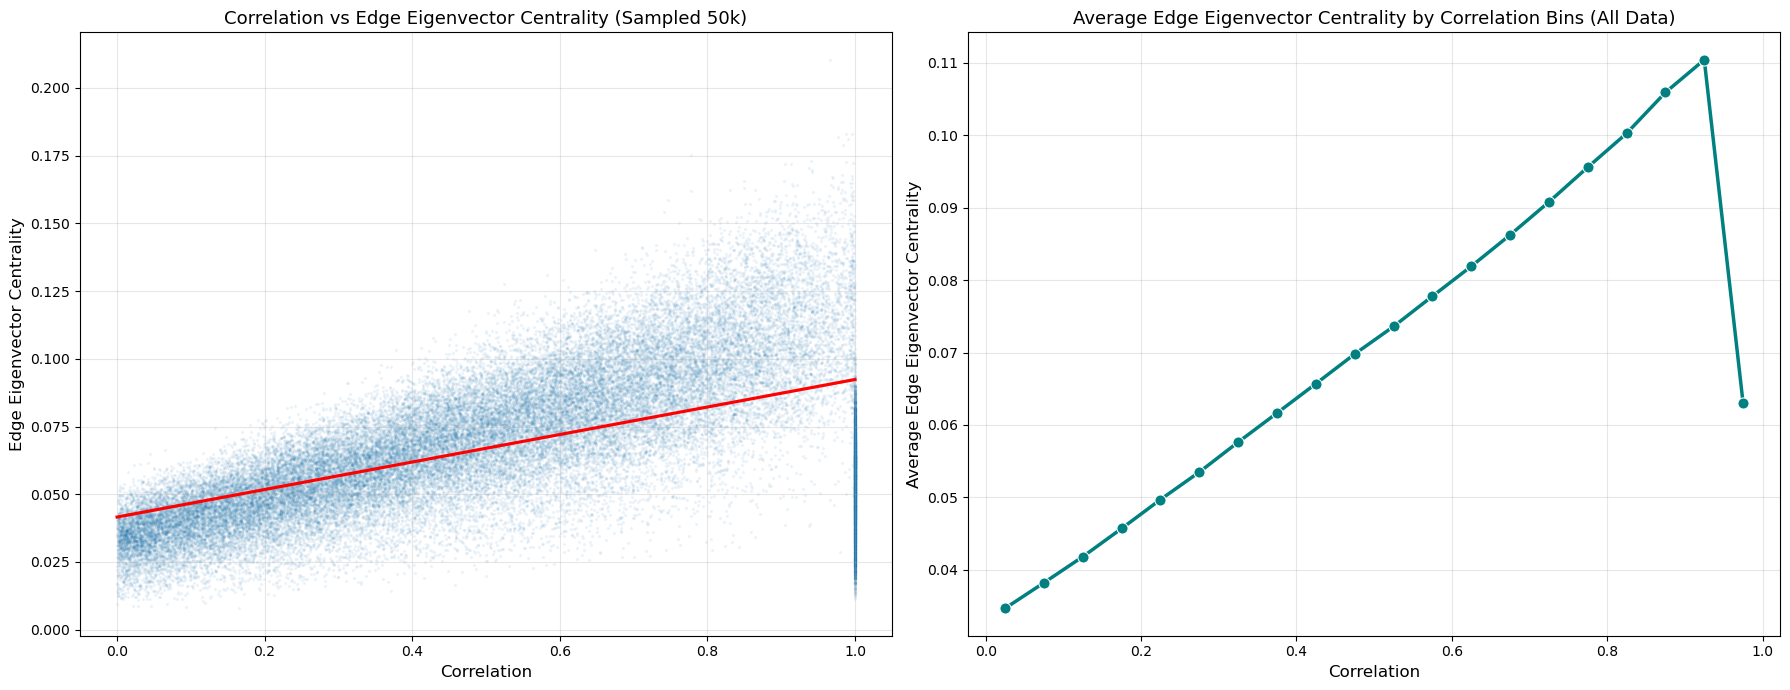

In [ ]:
# Create a DataFrame for plotting
df_plot = pd.DataFrame({
    'Correlation': correlation_values,
    'Edge Eigenvector': edge_ec_values
})

# Calculate Pearson and Spearman correlation coefficients
pearson_corr, p_p = stats.pearsonr(df_plot['Correlation'], df_plot['Edge Eigenvector'])
spearman_corr, p_s = stats.spearmanr(df_plot['Correlation'], df_plot['Edge Eigenvector'])
print(f"Pearson correlation coefficient: {pearson_corr:.4f} (p = {p_p:.4e})")
print(f"Spearman rank correlation coefficient: {spearman_corr:.4f} (p = {p_s:.4e})")

# Plot 1: Scatter plot with linear regression line (sampled for rendering efficiency)
df_sample = df_plot.sample(n=min(50000, len(df_plot)), random_state=42)

fig, axes = plt.subplots(1, 2, figsize=(18, 7))

sns.regplot(data=df_sample, x='Correlation', y='Edge Eigenvector', ax=axes[0],
            scatter_kws={'alpha':0.05, 's':2}, line_kws={'color':'red'})
axes[0].set_title('Correlation vs Edge Eigenvector Centrality (Sampled 50k)', fontsize=13)
axes[0].set_xlabel('Correlation', fontsize=12)
axes[0].set_ylabel('Edge Eigenvector Centrality', fontsize=12)
axes[0].grid(True, alpha=0.3)

# Plot 2: Binned Line Graph (using full dataset)
df_plot['Correlation Bin'] = pd.cut(df_plot['Correlation'], bins=np.linspace(0, 1, 21))
bin_means = df_plot.groupby('Correlation Bin', observed=True)['Edge Eigenvector'].mean().reset_index()
bin_means['Correlation Midpoint'] = bin_means['Correlation Bin'].apply(lambda x: x.mid).astype(float)

sns.lineplot(data=bin_means, x='Correlation Midpoint', y='Edge Eigenvector', marker='o', ax=axes[1], color='teal', linewidth=2.5, markersize=8)
axes[1].set_title('Average Edge Eigenvector Centrality by Correlation Bins (All Data)', fontsize=13)
axes[1].set_xlabel('Correlation', fontsize=12)
axes[1].set_ylabel('Average Edge Eigenvector Centrality', fontsize=12)
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
# plt.savefig('correlation_vs_edge_eigenvector.png', dpi=300, bbox_inches='tight')
plt.show()

# Deduction: The Hypothesis is Confirmed (Strong Positive Relationship)

Unlike **Edge Betweenness Centrality** (which peaks around ~0.6 and drops sharply afterward because high-correlation edges are internal within dense cliques rather than acting as inter-module bridges), **Edge Eigenvector Centrality** exhibits a statistically significant, robust **positive correlation** ($r = 0.5722, \rho = 0.5900, p < 0.0001$) with edge correlation.

### Network Science Interpretation:
1. **Embeddedness in Dense Core Clusters**: In network topology, eigenvector centrality measures how connected an edge is to other highly central, influential edges. Edges residing within dense, strongly connected cliques or functional cores naturally connect to many other high-weight edges in the line graph ($L$).
2. **Monotonically Increasing Trend**: The binned mean line plot confirms that across the vast majority of the correlation range ($0.0 \rightarrow 0.95$), average edge eigenvector centrality climbs steadily from ~0.035 at near-zero correlation up to ~0.110 at $0.925$.
3. **Extreme Edge Cases ($>0.95$)**: A slight drop occurs in the extreme tail ($>0.95$, midpoint $0.975$), which typically represents very small sample sizes or isolated artifacts (e.g., highly redundant twin channels or isolated pairs that are strongly correlated with each other but disconnected from the broader brain functional core).